# Chest X-Ray Pneumonia Classification
### Deep Learning with PyTorch & Transfer Learning (ResNet18)

**Author:** Muhammad Hilal
**Dataset:** [Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia)

---
## Project Overview
This notebook implements a Convolutional Neural Network (CNN) using Transfer Learning to classify Chest X-Ray images into two categories:
1. **NORMAL**
2. **PNEUMONIA**

### Techniques Used:
- **Transfer Learning:** Pre-trained ResNet18 on ImageNet.
- **Class Imbalance Handling:** WeightedRandomSampler and weighted CrossEntropyLoss.
- **Data Augmentation:** Random flips, rotations, and color jitter.
- **Early Stopping:** To prevent overfitting.
- **Explainable AI (XAI):** Grad-CAM visualization to interpret model predictions.

# Cell 1: Imports & Reproducibility

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import datasets, transforms, models
from tqdm import tqdm
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, roc_curve, auc, precision_recall_curve, average_precision_score)

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


# Cell 2: Configuration & Hyperparameters

In [2]:
#  UPDATE THIS PATH IF YOUR DATASET LOCATION CHANGES
DATA_DIR = "/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray" 

# Training Hyperparameters
BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 1e-3
PATIENCE = 5  # Early stopping patience

print(f"Dataset Directory: {DATA_DIR}")
print(f"Batch Size: {BATCH_SIZE} | Epochs: {EPOCHS} | LR: {LEARNING_RATE}")

Dataset Directory: /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray
Batch Size: 32 | Epochs: 20 | LR: 0.001


# Cell 3: Data Loading and Augmentation

In [3]:
print("Initializing Data Transforms...")
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("Loading Datasets...")
train_dataset = datasets.ImageFolder(os.path.join(DATA_DIR, 'train'), transform=train_transforms)
val_dataset = datasets.ImageFolder(os.path.join(DATA_DIR, 'val'), transform=val_transforms)
test_dataset = datasets.ImageFolder(os.path.join(DATA_DIR, 'test'), transform=val_transforms)

# Handle Class Imbalance using WeightedRandomSampler
targets = [label for _, label in train_dataset]
class_counts = torch.bincount(torch.tensor(targets))
class_weights = 1.0 / class_counts.float()
sample_weights = class_weights[torch.tensor(targets)]
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

print("Creating DataLoaders...")
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

classes = train_dataset.classes
print(f"Data loaded successfully! Classes: {classes}")
print(f"Train size: {len(train_dataset)} | Val size: {len(val_dataset)} | Test size: {len(test_dataset)}")

Initializing Data Transforms...
Loading Datasets...
Creating DataLoaders...
Data loaded successfully! Classes: ['NORMAL', 'PNEUMONIA']
Train size: 5216 | Val size: 16 | Test size: 624


# Cell 4: Model Definition (ResNet18)

In [4]:
print("Initializing ResNet18 Model...")
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze the backbone layers
for param in model.parameters():
    param.requires_grad = False 

# Replace the final fully connected layer
num_ftrs = model.fc.in_features
model.fc = nn.Sequential(nn.Dropout(0.5), nn.Linear(num_ftrs, len(classes)))

model = model.to(device)

# Loss function with class weights (Normal=0, Pneumonia=1)
criterion = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0]).to(device)) 

# Optimizer and Scheduler
optimizer = optim.Adam(model.fc.parameters(), lr=LEARNING_RATE)
scheduler = lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)

print("Model initialized and moved to device.")

Initializing ResNet18 Model...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 182MB/s]


Model initialized and moved to device.


# Cell 5: Training and Evaluation Functions

In [5]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for inputs, labels in tqdm(dataloader, desc="Training", leave=False):
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    return running_loss / total, correct / total

def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for inputs, labels in tqdm(dataloader, desc="Evaluating", leave=False):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * inputs.size(0)
            probs = torch.softmax(outputs, dim=1)[:, 1]
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return running_loss / total, correct / total, all_labels, all_preds, all_probs

# Cell 6: Training Loop with Early Stopping

In [6]:
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_loss = float('inf')
epochs_no_improve = 0

print("Starting Training...")
for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc, _, _, _ = evaluate(model, val_loader, criterion, device)
    scheduler.step()
    
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)
    
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_model.pth")
        print("Model saved!")
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print("Early stopping triggered.")
            break

Starting Training...

Epoch 1/20


Train Loss: 0.3999 | Train Acc: 0.7763
Val Loss: 0.2826 | Val Acc: 0.8125
Model saved!

Epoch 2/20


Train Loss: 0.2774 | Train Acc: 0.8662
Val Loss: 0.3192 | Val Acc: 0.7500

Epoch 3/20


Train Loss: 0.2623 | Train Acc: 0.8700
Val Loss: 0.2750 | Val Acc: 0.7500
Model saved!

Epoch 4/20


Train Loss: 0.2686 | Train Acc: 0.8752
Val Loss: 0.2404 | Val Acc: 0.8125
Model saved!

Epoch 5/20


...

Train Loss: 0.2689 | Train Acc: 0.8735
Val Loss: 0.2243 | Val Acc: 0.8125

Epoch 8/20


Train Loss: 0.2544 | Train Acc: 0.8823
Val Loss: 0.2274 | Val Acc: 0.8125

Epoch 9/20


Train Loss: 0.2600 | Train Acc: 0.8779
Val Loss: 0.2875 | Val Acc: 0.8125

Epoch 10/20


Train Loss: 0.2447 | Train Acc: 0.8859
Val Loss: 0.2355 | Val Acc: 0.8125

Epoch 11/20


Train Loss: 0.2349 | Train Acc: 0.8892
Val Loss: 0.2238 | Val Acc: 0.8125
Early stopping triggered.


# Cell 7: Final Test Evaluation

In [7]:
print("\n--- Testing Best Model ---")
model.load_state_dict(torch.load("best_model.pth"))
test_loss, test_acc, y_true, y_pred, y_probs = evaluate(model, test_loader, criterion, device)

print(f"\nTest Accuracy: {test_acc:.4f}")
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=classes))
print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))
print(f"\nROC-AUC Score: {roc_auc_score(y_true, y_probs):.4f}")


--- Testing Best Model ---



Test Accuracy: 0.8958

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.92      0.79      0.85       234
   PNEUMONIA       0.89      0.96      0.92       390

    accuracy                           0.90       624
   macro avg       0.90      0.88      0.89       624
weighted avg       0.90      0.90      0.89       624


Confusion Matrix:
[[186  48]
 [ 17 373]]

ROC-AUC Score: 0.9554


# Cell 8: Graph-1 Class Distribution (EDA)

/tmp/ipykernel_23/2194634695.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=targets, palette='viridis')


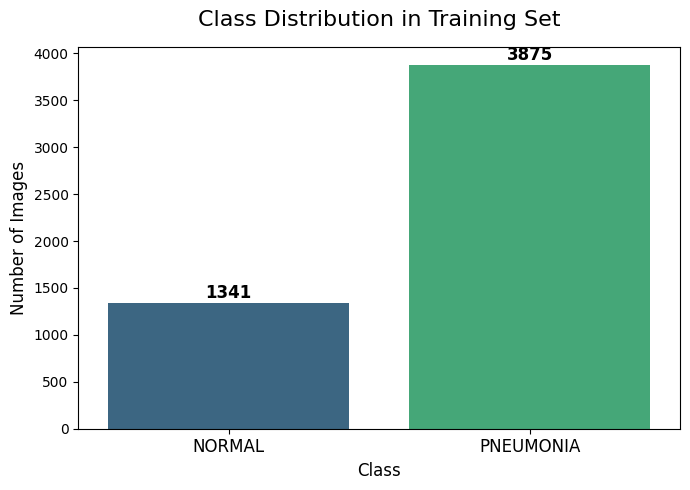

In [8]:
plt.figure(figsize=(7, 5))
sns.countplot(x=targets, palette='viridis')
plt.title('Class Distribution in Training Set', fontsize=16, pad=15)
plt.xlabel('Class', fontsize=12)
plt.ylabel('Number of Images', fontsize=12)
plt.xticks(ticks=[0, 1], labels=classes, fontsize=12)
for i, count in enumerate(np.bincount(targets)):
    plt.text(i, count + 50, str(count), ha='center', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=300)
plt.show()

# Cell 9: Graph-2 Training History

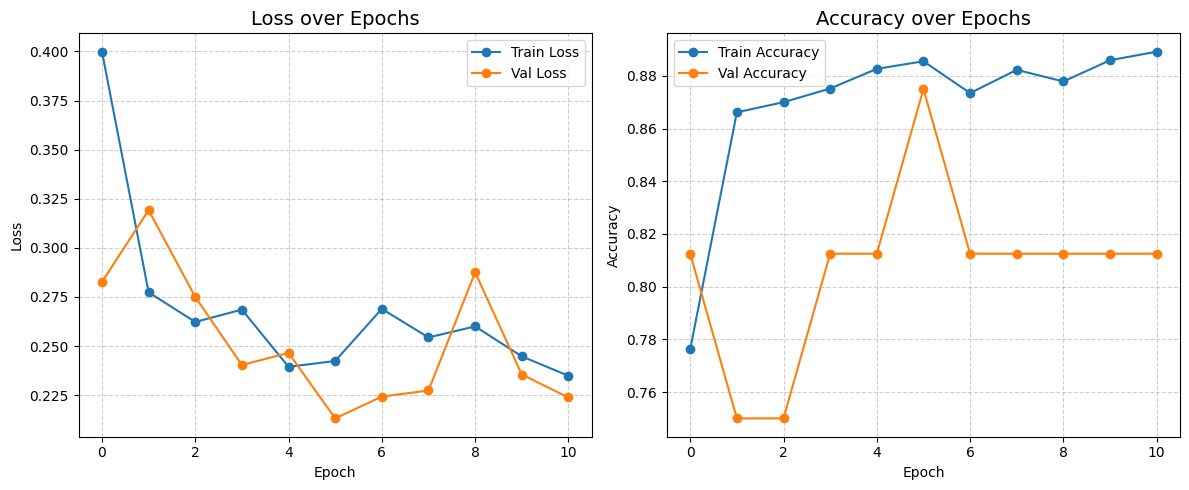

In [9]:
plt.figure(figsize=(12, 5))

# Loss Plot
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss', marker='o')
plt.plot(history['val_loss'], label='Val Loss', marker='o')
plt.title('Loss over Epochs', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Accuracy Plot
plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='Train Accuracy', marker='o')
plt.plot(history['val_acc'], label='Val Accuracy', marker='o')
plt.title('Accuracy over Epochs', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('training_history.png', dpi=300)
plt.show()

# Cell 10: Graph-3 Confusion Matrix Heatmap

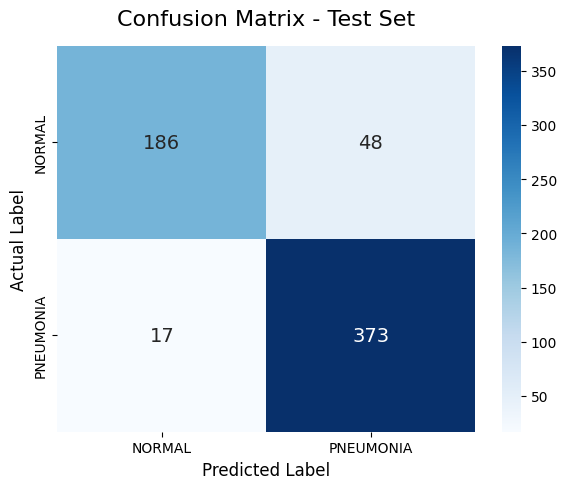

In [10]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes,annot_kws={"size": 14})
plt.title('Confusion Matrix - Test Set', fontsize=16, pad=15)
plt.ylabel('Actual Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()

# Cell 11: Graph-4 ROC Curve

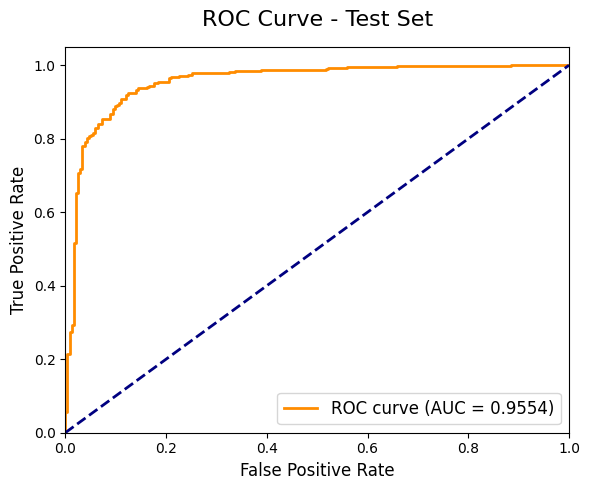

In [11]:
fpr, tpr, _ = roc_curve(y_true, y_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve - Test Set', fontsize=16, pad=15)
plt.legend(loc="lower right", fontsize=12)
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=300)
plt.show()

# Cell 12: Graph 5 - Precision-Recall Curve

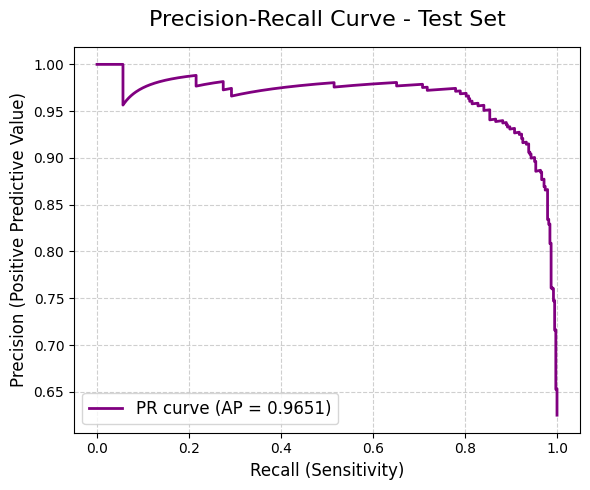

In [12]:
precision, recall, _ = precision_recall_curve(y_true, y_probs)
avg_precision = average_precision_score(y_true, y_probs)

plt.figure(figsize=(6, 5))
plt.plot(recall, precision, color='purple', lw=2, label=f'PR curve (AP = {avg_precision:.4f})')
plt.xlabel('Recall (Sensitivity)', fontsize=12)
plt.ylabel('Precision (Positive Predictive Value)', fontsize=12)
plt.title('Precision-Recall Curve - Test Set', fontsize=16, pad=15)
plt.legend(loc="lower left", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('precision_recall_curve.png', dpi=300)
plt.show()

# Cell 13: Graph 6 - Sample Predictions Grid

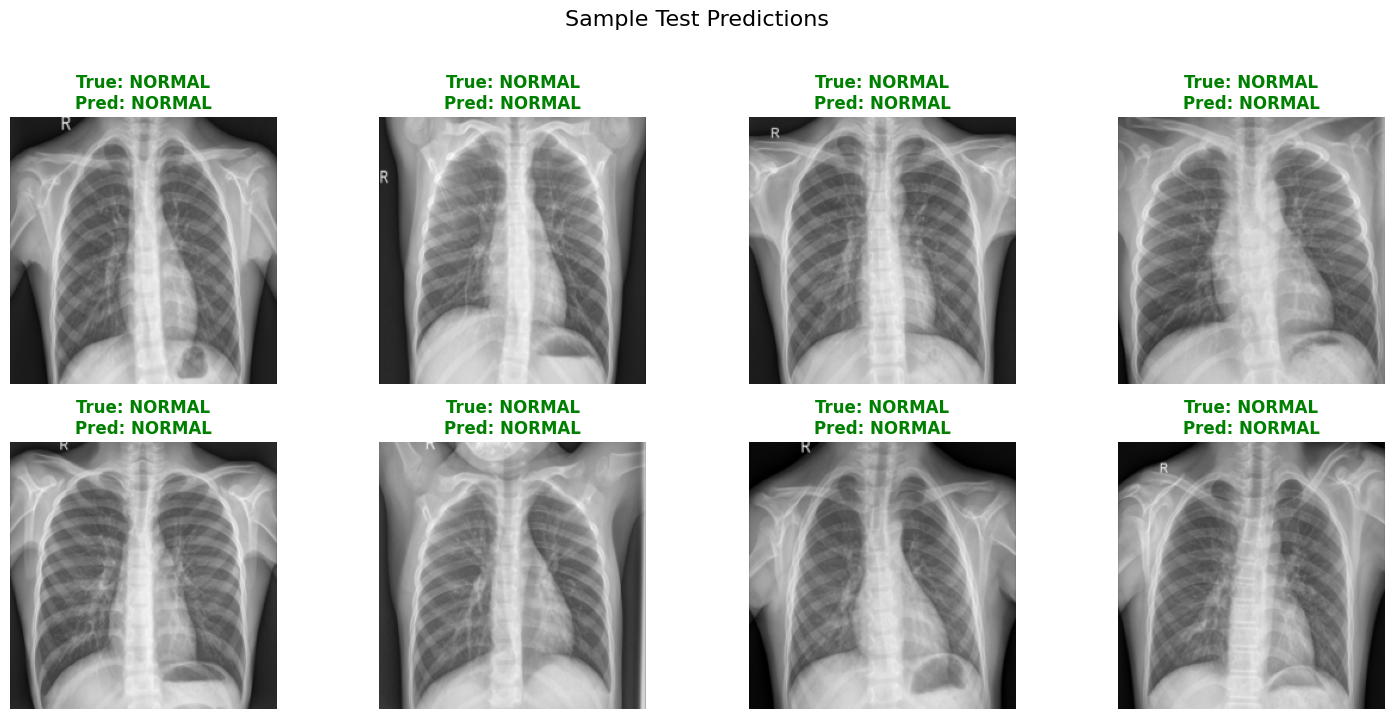

In [13]:
dataiter = iter(test_loader)
images, labels = next(dataiter)
model.eval()
with torch.no_grad():
    outputs = model(images.to(device))
    _, preds = torch.max(outputs, 1)

inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
axes = axes.ravel()

for idx in range(8):
    img = inv_normalize(images[idx]).permute(1, 2, 0).cpu().numpy()
    img = np.clip(img, 0, 1)
    axes[idx].imshow(img, cmap='gray')
    axes[idx].axis('off')
    
    true_label = classes[labels[idx]]
    pred_label = classes[preds[idx]]
    color = 'green' if true_label == pred_label else 'red'
    axes[idx].set_title(f"True: {true_label}\nPred: {pred_label}", 
                        color=color, fontsize=12, fontweight='bold')

plt.suptitle('Sample Test Predictions', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig('sample_predictions.png', dpi=300)
plt.show()

# Cell 14: Graph 7 - Grad-CAM Explainability


Generating Grad-CAM...


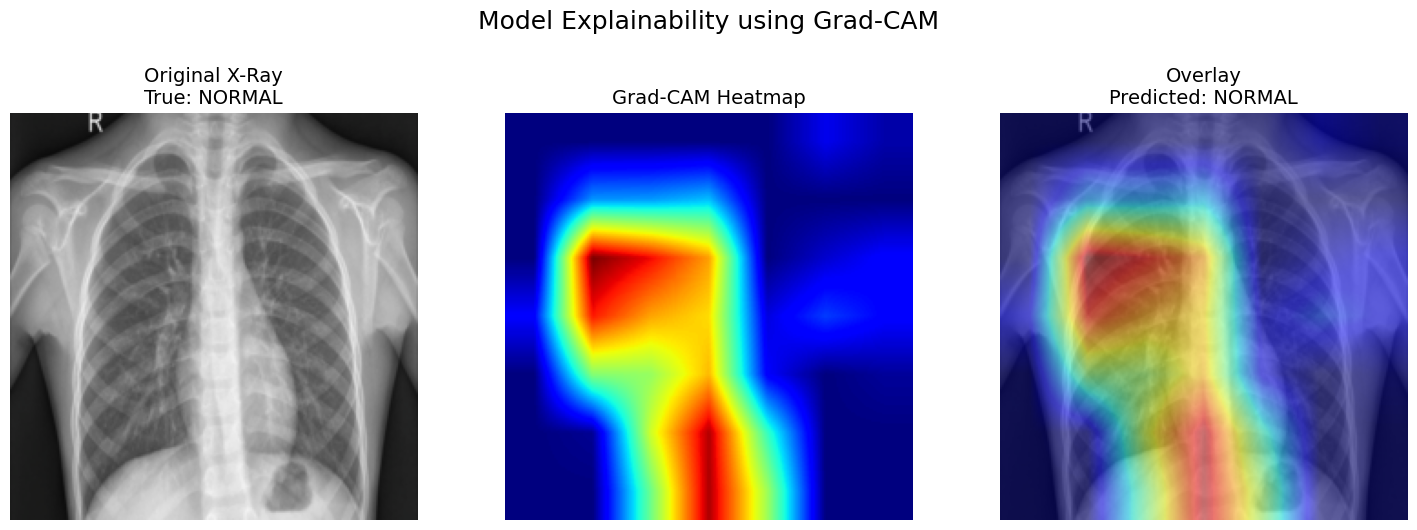


 All graphs generated and saved as high-resolution PNGs!


In [14]:
print("\nGenerating Grad-CAM...")

# FIX: Temporarily unfreeze the model so gradients flow for Grad-CAM
model.requires_grad_(True) 

img_tensor, label = test_dataset[0] 
input_tensor = img_tensor.unsqueeze(0).to(device)
model.eval()

target_layer = model.layer4[-1]
gradients = []
activations = []

def save_gradient(grad): 
    gradients.append(grad)

def forward_hook(module, input, output):
    activations.append(output)
    output.register_hook(save_gradient)

handle = target_layer.register_forward_hook(forward_hook)
output = model(input_tensor)
pred_class = output.argmax(dim=1).item()
score = output[0, pred_class]
model.zero_grad()
score.backward()

grads = gradients[0].cpu().data.numpy()[0]
acts = activations[0].cpu().data.numpy()[0]
weights = np.mean(grads, axis=(1, 2))
cam = np.zeros(acts.shape[1:], dtype=np.float32)
for i, w in enumerate(weights):
    cam += w * acts[i, :, :]

cam = np.maximum(cam, 0)
cam = cv2.resize(cam, (224, 224))
cam = cam - np.min(cam)
cam = cam / np.max(cam)

img_orig = inv_normalize(img_tensor).permute(1, 2, 0).cpu().numpy()
img_orig = np.clip(img_orig, 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_orig, cmap='gray')
axes[0].set_title(f"Original X-Ray\nTrue: {classes[label]}", fontsize=14)
axes[0].axis('off')

axes[1].imshow(cam, cmap='jet')
axes[1].set_title("Grad-CAM Heatmap", fontsize=14)
axes[1].axis('off')

axes[2].imshow(img_orig, cmap='gray')
axes[2].imshow(cam, cmap='jet', alpha=0.5)
axes[2].set_title(f"Overlay\nPredicted: {classes[pred_class]}", fontsize=14)
axes[2].axis('off')

plt.suptitle('Model Explainability using Grad-CAM', fontsize=18, y=1.05)
plt.tight_layout()
plt.savefig('gradcam.png', dpi=300)
plt.show()

handle.remove()
print("\n All graphs generated and saved as high-resolution PNGs!")

# Cell 15: Grad-CAM for Pneumonia vs. Normal (Comparison)


Generating Grad-CAM for Pneumonia vs Normal...


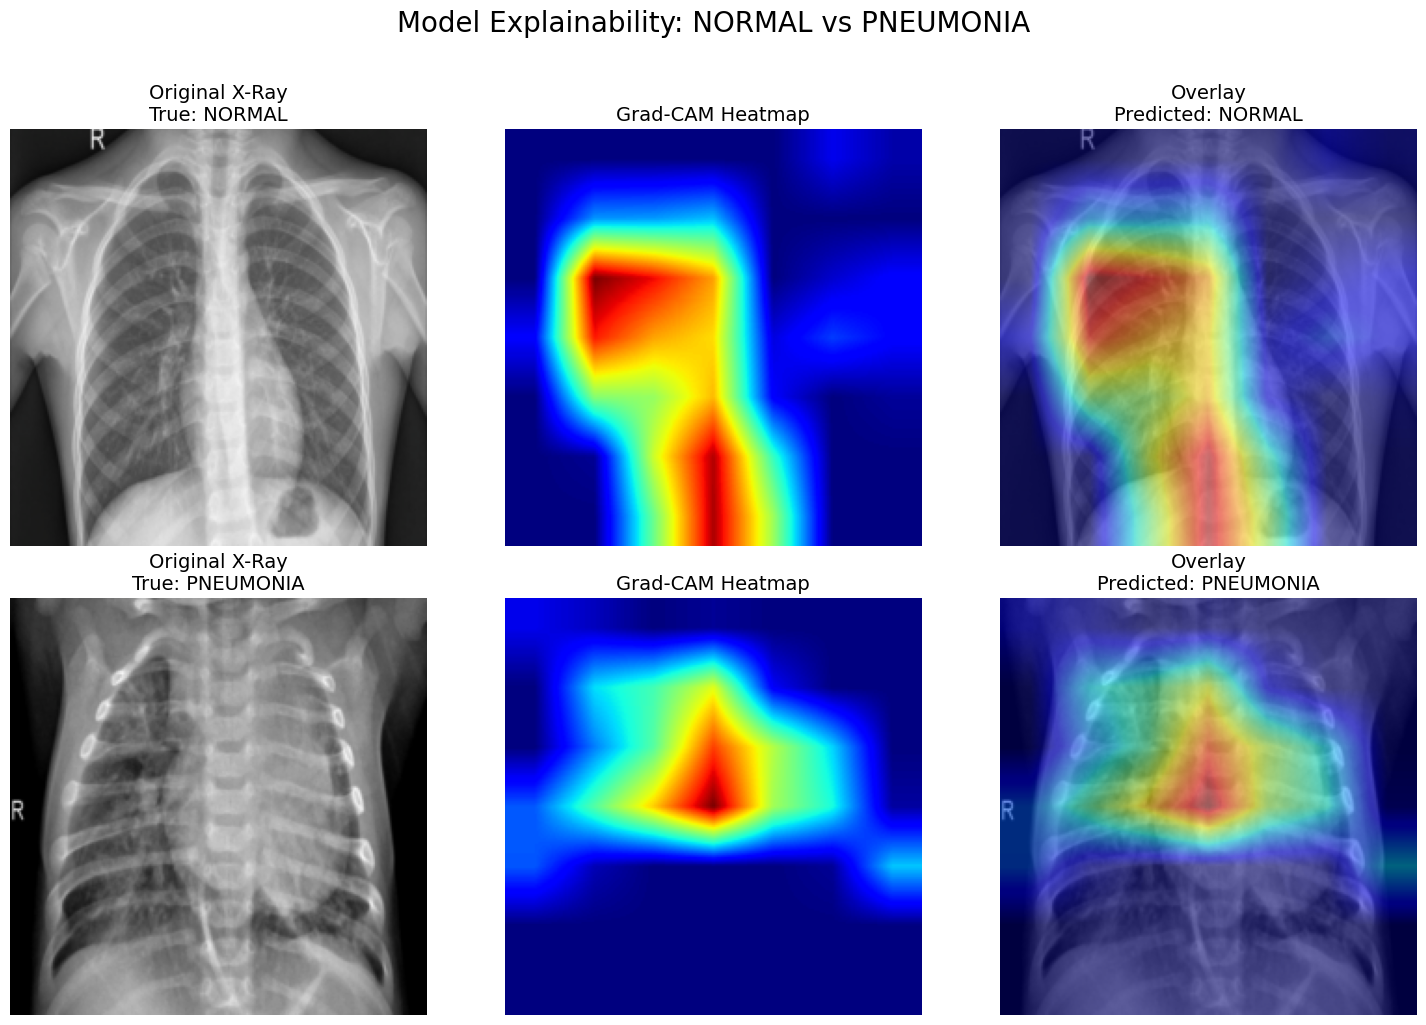

Comparison Grad-CAM saved as 'gradcam_pneumonia_vs_normal.png'


In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision import transforms

print("\nGenerating Grad-CAM for Pneumonia vs Normal...")

# 1. Ensure gradients are enabled for the backbone
model.requires_grad_(True)
model.eval()

# 2. Find a NORMAL and a PNEUMONIA image from the test set
normal_idx, pneumonia_idx = None, None
for i in range(len(test_dataset)):
    _, label = test_dataset[i]
    if label == 0 and normal_idx is None:       # 0 = NORMAL
        normal_idx = i
    elif label == 1 and pneumonia_idx is None:  # 1 = PNEUMONIA
        pneumonia_idx = i
    if normal_idx is not None and pneumonia_idx is not None:
        break

# 3. Define the Grad-CAM generation function
def generate_gradcam(model, img_tensor, device):
    input_tensor = img_tensor.unsqueeze(0).to(device)
    
    # Hook into the last convolutional layer
    target_layer = model.layer4[-1]
    gradients = []
    activations = []
    
    def save_gradient(grad):
        gradients.append(grad)
        
    def forward_hook(module, input, output):
        activations.append(output)
        output.register_hook(save_gradient)
        
    handle = target_layer.register_forward_hook(forward_hook)
    
    # Forward pass
    output = model(input_tensor)
    pred_class = output.argmax(dim=1).item()
    score = output[0, pred_class]
    
    # Backward pass
    model.zero_grad()
    score.backward()
    
    # Generate CAM
    grads = gradients[0].cpu().data.numpy()[0]
    acts = activations[0].cpu().data.numpy()[0]
    weights = np.mean(grads, axis=(1, 2))
    
    cam = np.zeros(acts.shape[1:], dtype=np.float32)
    for i, w in enumerate(weights):
        cam += w * acts[i, :, :]
        
    cam = np.maximum(cam, 0) # ReLU
    cam = cv2.resize(cam, (224, 224))
    cam = cam - np.min(cam)
    cam = cam / np.max(cam) # Normalize 0-1
    
    handle.remove()
    return cam, pred_class

# 4. Denormalization function for plotting
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

# 5. Plotting
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for row, (idx, title_prefix) in enumerate(zip([normal_idx, pneumonia_idx], ["NORMAL", "PNEUMONIA"])):
    if idx is None:
        continue
        
    img_tensor, true_label = test_dataset[idx]
    cam, pred_class = generate_gradcam(model, img_tensor, device)
    
    # Prepare image for display
    img_orig = inv_normalize(img_tensor).permute(1, 2, 0).cpu().numpy()
    img_orig = np.clip(img_orig, 0, 1)
    
    # Column 1: Original
    axes[row, 0].imshow(img_orig, cmap='gray')
    axes[row, 0].set_title(f"Original X-Ray\nTrue: {classes[true_label]}", fontsize=14)
    axes[row, 0].axis('off')
    
    # Column 2: Grad-CAM Heatmap
    axes[row, 1].imshow(cam, cmap='jet')
    axes[row, 1].set_title(f"Grad-CAM Heatmap", fontsize=14)
    axes[row, 1].axis('off')
    
    # Column 3: Overlay
    axes[row, 2].imshow(img_orig, cmap='gray')
    axes[row, 2].imshow(cam, cmap='jet', alpha=0.5)
    axes[row, 2].set_title(f"Overlay\nPredicted: {classes[pred_class]}", fontsize=14)
    axes[row, 2].axis('off')

plt.suptitle('Model Explainability: NORMAL vs PNEUMONIA', fontsize=20, y=1.02)
plt.tight_layout()
plt.savefig('gradcam_pneumonia_vs_normal.png', dpi=300)
plt.show()
print("Comparison Grad-CAM saved as 'gradcam_pneumonia_vs_normal.png'")